## Inequalities in Vegetation Access in Urban Communities

### What will we discuss?
In this article, we will be covering how historical racial discrimination and redlining has led to modern inequalities in access to vegetation for the inhabitants of Oakland, California, as well as how our understanding of it impacts what we know about racism as a whole in the United States.




### Historical Drivers of Urban Environmental Disparities
In Science, Schell et al. (2020) demonstrate how 20th-century housing policies—specifically redlining and classist zoning practices—shaped modern urban ecological patterns. These historical socioeconomic decisions created lasting structural inequities in canopy cover, microclimates, and biodiversity across urban communities. Analyzing these historical drivers is essential for understanding present-day environmental disparities and informing equitable urban planning and conservation strategies moving forward.

In [1]:
import urllib.request
import ibis
import geopandas as gpd
import leafmap

url = "https://dsl.richmond.edu/panorama/redlining/static/citiesData/CAOakland1937/geojson.json"
urllib.request.urlretrieve(url, "oakland_redlining.geojson")

gdf_raw = gpd.read_file("oakland_redlining.geojson")
table_ibis = ibis.memtable(gdf_raw.drop(columns=['geometry']))

filtered_ibis = table_ibis.filter(table_ibis['grade'].isin(['A', 'B', 'C', 'D']))
df_filtered_indices = filtered_ibis.select(['area_id', 'grade']).execute()

neighborhoods_gdf = gdf_raw[gdf_raw['area_id'].isin(df_filtered_indices['area_id'])].copy()

holc_colors = {'A': '#4daf4a', 'B': '#377eb8', 'C': '#ffff33', 'D': '#e41a1c'}
neighborhoods_gdf['color'] = neighborhoods_gdf['grade'].map(holc_colors)

m = leafmap.Map(center=[37.80, -122.27], zoom=11, draw_control=False)
m.add_basemap("OpenStreetMap")
m.add_gdf(
    neighborhoods_gdf,
    layer_name="Oakland Redlining",
    fill_colors=neighborhoods_gdf['color'].tolist(),
    info_mode="on_hover"
)
m

OpenStreetMap has been already added before.


Map(center=[37.8, -122.27], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title', 'zoom_…

## Satellite Imagery and NDVI
To quantify local environmental disparities, we retrieved Sentinel-2 satellite imagery via the Earth Search STAC catalog and calculated the Normalized Difference Vegetation Index (NDVI). By leveraging the contrast between near-infrared (NIR) and red light reflectance bands, we mapped the spatial distribution of urban tree canopy across Oakland, California. This spatial framework provides a quantitative baseline to evaluate the broader ecological and public health implications for Oakland residents.

In [2]:
import subprocess
import sys

subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q", "planetary-computer"
])

0

In [3]:
import pystac_client
import odc.stac
import leafmap

bbox = list(neighborhoods_gdf.total_bounds)
catalog = pystac_client.Client.open("https://earth-search.aws.element84.com/v1")

search = catalog.search(
    collections=["sentinel-2-l2a"],
    bbox=bbox,
    datetime="2023-06-01/2023-08-31",
    query={"eo:cloud_cover": {"lt": 5}}
)

items = search.item_collection()
selected_item = items[0]
(f"Found {len(items)} clear satellite images! Selected item: {selected_item.id}")

ds = odc.stac.load([selected_item], bands=["red", "nir"], bbox=bbox, resolution=10)
red = ds["red"].astype(float)
nir = ds["nir"].astype(float)
ndvi = (nir - red) / (nir + red)

ndvi_single = ndvi.isel(time=0)

m_raster = leafmap.Map(center=[37.80, -122.27], zoom=11)
m_raster.add_raster(ndvi_single, colormap="YlGn", layer_name="NDVI Raster")

m_raster


Map(center=[37.8098615, -122.2130425], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_tit…

## Integrating Raster and Vector Datasets
Next, we performed a spatial overlay by combining the raster-derived NDVI layer with the Home Owners' Loan Corporation (HOLC) redlining polygon vector data to compute zonal statistics. Aggregating vegetation metrics across historical HOLC security zones allows us to quantify mean canopy cover per neighborhood across Oakland. This computational approach establishes a direct link between historical housing classifications and present-day ecological metrics.


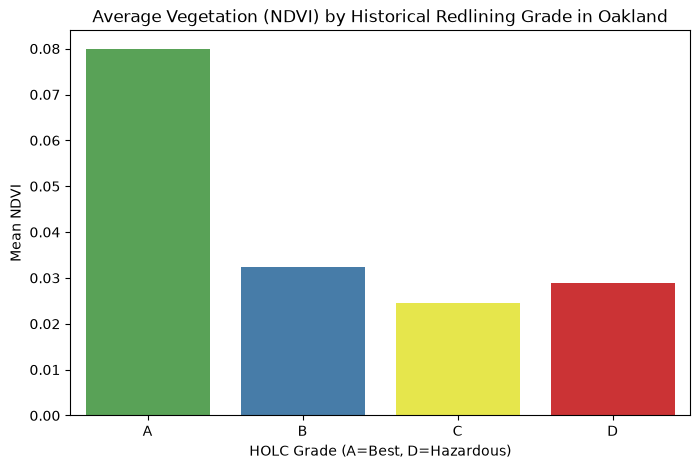

OpenStreetMap has been already added before.


Map(center=[37.8, -122.27], controls=(ZoomControl(options=['position', 'zoom_in_text', 'zoom_in_title', 'zoom_…

In [4]:
import urllib.request
import ibis
import geopandas as gpd
import pystac_client
import odc.stac
import rioxarray
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import leafmap

url = "https://dsl.richmond.edu/panorama/redlining/static/citiesData/CAOakland1937/geojson.json"
urllib.request.urlretrieve(url, "oakland_redlining.geojson")

gdf_raw = gpd.read_file("oakland_redlining.geojson")
table_ibis = ibis.memtable(gdf_raw.drop(columns=['geometry']))
filtered_ibis = table_ibis.filter(table_ibis['grade'].isin(['A', 'B', 'C', 'D']))
df_filtered_indices = filtered_ibis.select(['area_id', 'grade']).execute()

neighborhoods_gdf = gdf_raw[gdf_raw['area_id'].isin(df_filtered_indices['area_id'])].copy()
holc_colors = {'A': '#4daf4a', 'B': '#377eb8', 'C': '#ffff33', 'D': '#e41a1c'}
neighborhoods_gdf['color'] = neighborhoods_gdf['grade'].map(holc_colors)

bbox = list(neighborhoods_gdf.total_bounds)
catalog = pystac_client.Client.open("https://earth-search.aws.element84.com/v1")
search = catalog.search(
    collections=["sentinel-2-l2a"],
    bbox=bbox,
    datetime="2023-06-01/2023-08-31",
    query={"eo:cloud_cover": {"lt": 5}}
)
items = search.item_collection()

ds = odc.stac.load(
    [items[0]],
    bands=["red", "nir"],
    bbox=bbox,
    resolution=10
)

red = ds["red"].squeeze().astype("float32")
nir = ds["nir"].squeeze().astype("float32")
ndvi = (nir - red) / (nir + red)

ndvi_2d = ndvi.rio.write_crs(ds.odc.crs)
neighborhoods_proj = neighborhoods_gdf.to_crs(ndvi_2d.rio.crs)

means = []
for _, row in neighborhoods_proj.iterrows():
    try:
        minx, miny, maxx, maxy = row.geometry.bounds
        sub_raster = ndvi_2d.rio.slice_xy(minx=minx, maxy=maxy, maxx=maxx, miny=miny)
        clipped = sub_raster.rio.clip([row.geometry], neighborhoods_proj.crs, drop=True)
        val = float(clipped.mean().values)
    except Exception:
        val = None
    means.append(val)

neighborhoods_gdf['mean_ndvi'] = means
grade_summary = neighborhoods_gdf.groupby('grade')['mean_ndvi'].mean().reset_index()

plt.figure(figsize=(8, 5))
sns.barplot(
    data=grade_summary,
    x='grade',
    y='mean_ndvi',
    hue='grade',
    palette=holc_colors,
    order=['A', 'B', 'C', 'D'],
    legend=False
)
plt.title("Average Vegetation (NDVI) by Historical Redlining Grade in Oakland")
plt.xlabel("HOLC Grade (A=Best, D=Hazardous)")
plt.ylabel("Mean NDVI")
plt.savefig("web/bar_chart.png", bbox_inches='tight')
plt.show()
#
m_combined = leafmap.Map(center=[37.80, -122.27], zoom=11)
m_combined.add_basemap("OpenStreetMap")
m_combined.add_gdf(
    neighborhoods_gdf,
    layer_name="Zonal Stats Oakland Redlining",
    fill_colors=neighborhoods_gdf['color'].tolist(),
    info_mode="on_hover"
)
m_combined


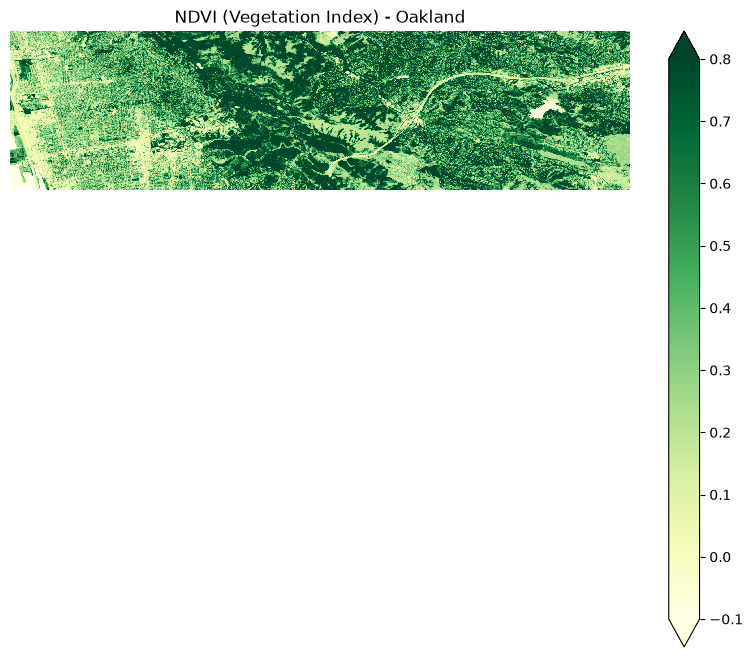

In [5]:
import odc.stac
import matplotlib.pyplot as plt

item = items[0]

ds = odc.stac.load(
    [item],
    bands=["red", "nir"],
    bbox=bbox,
    resolution=10
)

red = ds["red"].astype(float)
nir = ds["nir"].astype(float)
ndvi = (nir - red) / (nir + red)

plt.figure(figsize=(10, 8))
ndvi.isel(time=0).plot(cmap="YlGn", vmin=-0.1, vmax=0.8)
plt.title("NDVI (Vegetation Index) - Oakland")
plt.axis("off")
plt.show()


## Conclusion: Ecological Consequences of Historical Redlining
The resulting zonal statistics reveal a clear disparity in urban canopy cover across Oakland's historical HOLC security zones. Neighborhoods designated as Grade C ("Definitely Declining") and Grade D ("Hazardous") consistently exhibit significantly lower mean NDVI values relative to Grade A and B zones.

These spatial patterns align directly with the structural framework outlined by Schell et al. (2020), demonstrating how historical housing discrimination exerts a lingering legacy effect on urban ecosystems. Because discriminatory policies systematically restricted capital investment in marginalized communities, their ecological impacts—such as diminished vegetation cover, heightened microclimate temperatures, and reduced ecosystem services—persist long after formal policy repeal. Quantifying these spatial inequities provides the empirical foundation necessary to evaluate environmental justice initiatives and guide targeted, equitable urban planning interventions.

In [6]:
import os

os.makedirs("web", exist_ok=True)

plt.figure(figsize=(8, 5))
sns.barplot(
    data=grade_summary,
    x='grade',
    y='mean_ndvi',
    hue='grade',
    palette=holc_colors,
    order=['A', 'B', 'C', 'D'],
    legend=False
)
plt.title("Average Vegetation (NDVI) by Historical Redlining Grade in Oakland")
plt.xlabel("HOLC Grade (A=Best, D=Hazardous)")
plt.ylabel("Mean NDVI")
plt.savefig("web/bar_chart.png", bbox_inches='tight', dpi=300)
plt.close()

plt.figure(figsize=(10, 8))
ndvi_2d.plot(cmap="YlGn", vmin=-0.1, vmax=0.8)
plt.title("NDVI (Vegetation Index) - Oakland")
plt.axis("off")
plt.savefig("web/ndvi_plot.png", bbox_inches='tight', dpi=300)
plt.close()